<a href="https://colab.research.google.com/github/Kemtojp/sic_ia_2026/blob/main/ejercicios_estudiantes/clase08_grupo2A_ex_0403.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Coding Exercise #0403

### 1. Compare clustering algorithms:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.datasets import make_blobs, make_moons
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
import warnings
warnings.filterwarnings('ignore')           # Turn off the warnings.
%matplotlib inline

#### 1.1. Generate simulated data and visualize:

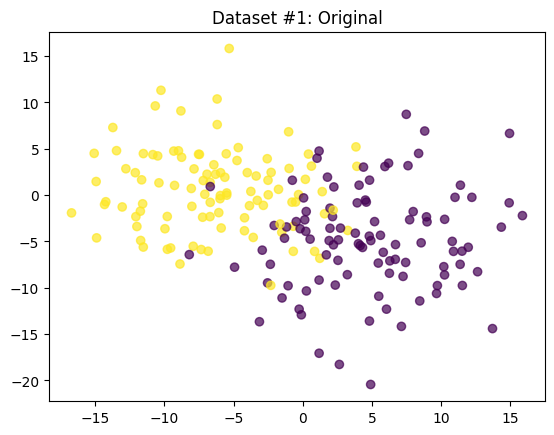

In [2]:
# Dataset #1.
X1, label1 = make_blobs(n_samples=200, n_features=2, centers=2, cluster_std = 5, random_state=123)
plt.scatter(X1[:, 0], X1[:, 1], c=label1, alpha=0.7)
plt.title('Dataset #1: Original')
plt.show()

Qué vemos: Dos grupos redondeados con sus etiquetas reales.   

El desafío: Tienen mucha dispersión (cluster_std=5), por lo que varios puntos se mezclan en el centro.   

Objetivo: Ver qué tan bien traza la frontera cada modelo en esa zona solapada.

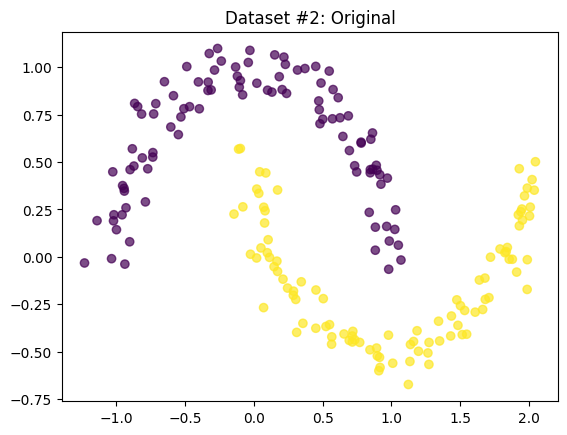

In [3]:
# Dataset #2.
X2, label2 = make_moons(n_samples=200, noise=0.08, random_state=123)
plt.scatter(X2[:, 0], X2[:, 1], c=label2, alpha=0.7)
plt.title('Dataset #2: Original')
plt.show()

Qué vemos: Dos grupos entrelazados con forma de medialuna.   

El desafío: No tienen forma circular ni lineal; son curvas continuas.   

Objetivo: Poner a prueba si un modelo puede seguir la forma del dato o si solo sabe trazar líneas rectas.

#### 1.2. Apply k-means clustering and visualize:

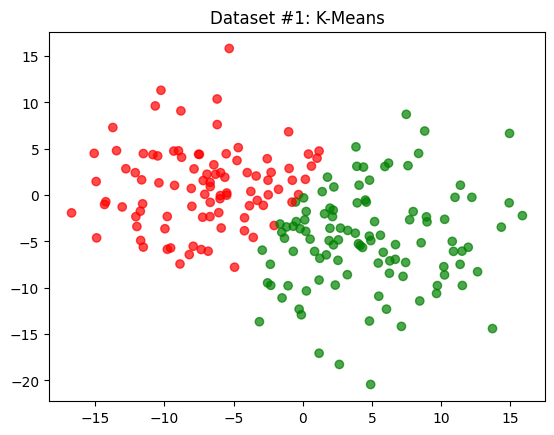

In [4]:
# Dataset #1 and two clusters.
kmeans = KMeans(n_clusters=2, random_state=123, n_init='auto')                 # kmeans object for 2 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X1)                                                 # Unsupervised learning => Only X1.
myColors = {0: 'red', 1: 'green'}                                 # Define a color palette: 0~1.
plt.scatter(X1[:, 0], X1[:, 1], c=pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #1: K-Means')
plt.show()

Resultado: Funciona bien.   

Comportamiento: Separa los datos con una línea recta entre ambos centros.   

Detalle: Al ser grupos redondeados, la división tiene sentido, aunque los puntos mezclados del centro quedan asignados obligatoriamente al centroide más cercano.

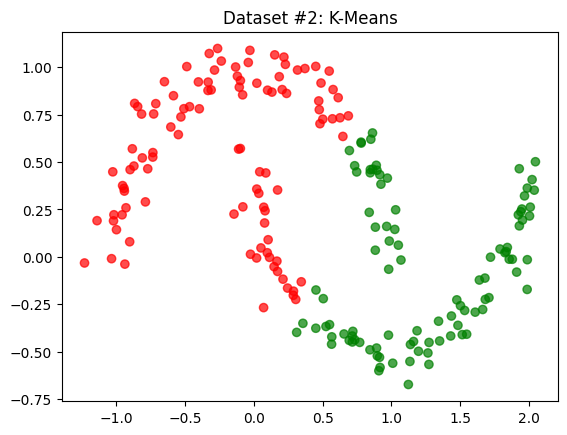

In [5]:
# Dataset #2 and two clusters.
kmeans = KMeans(n_clusters=2, random_state=123, n_init='auto')     # kmeans object for 2 clusters. radom_state=123 means deterministic initialization.
kmeans.fit(X2)                                                     # Unsupervised learning => Only X1.
myColors = {0: 'red', 1: 'green'}                                    # Define a color palette: 0~1.
plt.scatter(X2[:,0], X2[:, 1], c=pd.Series(kmeans.labels_).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #2: K-Means')
plt.show()

Resultado: Falla por completo.   

Comportamiento: Corta las dos medialunas por la mitad con una línea vertical.   

Causa: K-Means asume formas circulares y solo sabe dividir con líneas rectas; es incapaz de seguir la curvatura natural de los datos.

#### 1.3. Apply agglomerative clustering and visualize:

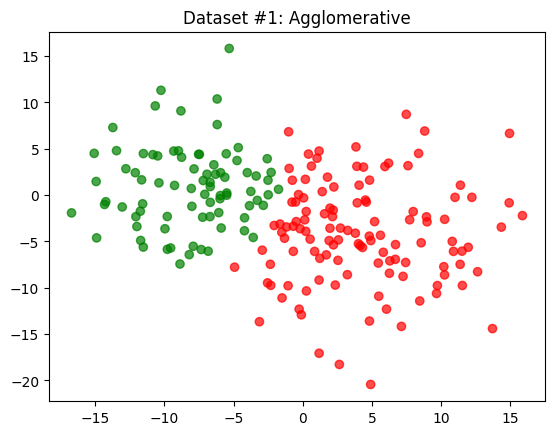

In [6]:
# Dataset #1 and two clusters.
agglo = AgglomerativeClustering(n_clusters=2)
agglo.fit(X1)
myColors = {0: 'red', 1: 'green'}                                 # Define a color palette: 0~1.
plt.scatter(X1[:, 0], X1[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #1: Agglomerative')
plt.show()

Resultado: Funciona bien.   

Comportamiento: Divide los datos en dos bloques compactos, muy parecido a K-Means.   

Causa: Por defecto busca formar grupos redondos y parejos, lo que encaja con este tipo de datos.

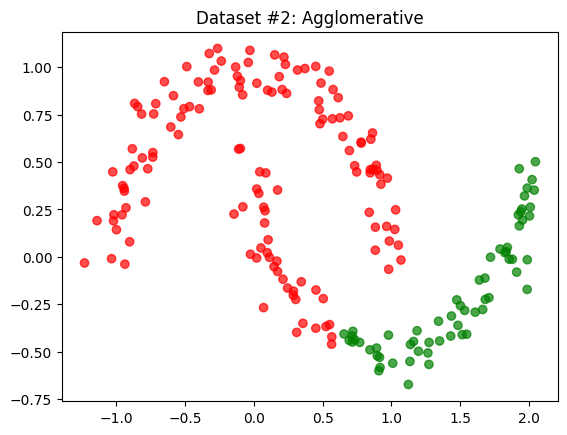

In [7]:
# Dataset #2 and two clusters.
agglo = AgglomerativeClustering(n_clusters=2)
agglo.fit(X2)
myColors = {0: 'red', 1: 'green'}                                 # Define a color palette: 0~1.
plt.scatter(X2[:, 0], X2[:, 1], c=pd.Series(agglo.labels_).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #2: Agglomerative')
plt.show()

Resultado: Falla.   

Comportamiento: Corta las curvas y mete casi todo en el grupo rojo, dejando solo una punta en verde.   

Causa: Al buscar grupos compactos y no la continuidad de la curva, no logra entender la forma de las medialunas.

#### 1.4. Apply hierarchical clustering and visualize:

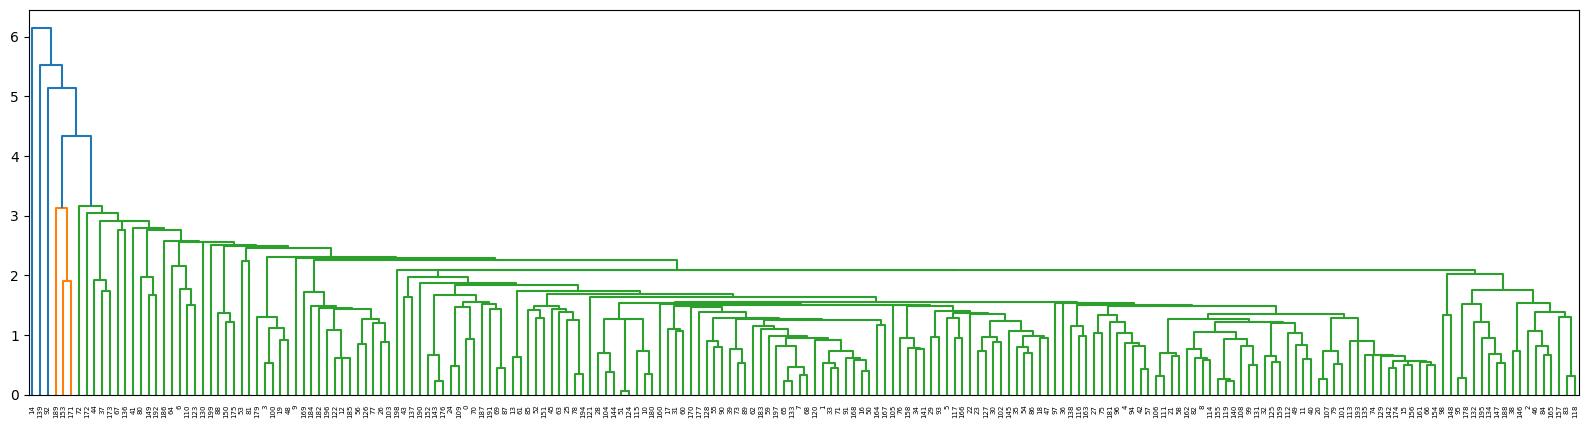

In [8]:
# Dataset #1 and show dendrogram.
myLinkage = linkage(X1, method='single')       # Cluster hierarchically using single linkage.
plt.figure(figsize=(20, 5))
dendrogram(myLinkage)
plt.show()

In [9]:
# Dataset #1 and clusters by cutting the dendrogram.
labels = fcluster(myLinkage, 5, criterion='distance')                      #  Cut at the height (distance) = 5 <= change this value at will.
pd.Series(labels).value_counts()

,count
1,197
4,1
2,1
3,1


Resultado: Falla por completo.   

Comportamiento: Metió casi todos los puntos en un solo grupo gigante (197) y dejó 3 puntos aislados como grupos individuales.   

Causa: El enlace simple (single) conecta puntos por distancia mínima. Al estar los datos mezclados en el centro, se genera un "efecto cadena" que une todo en una sola masa.

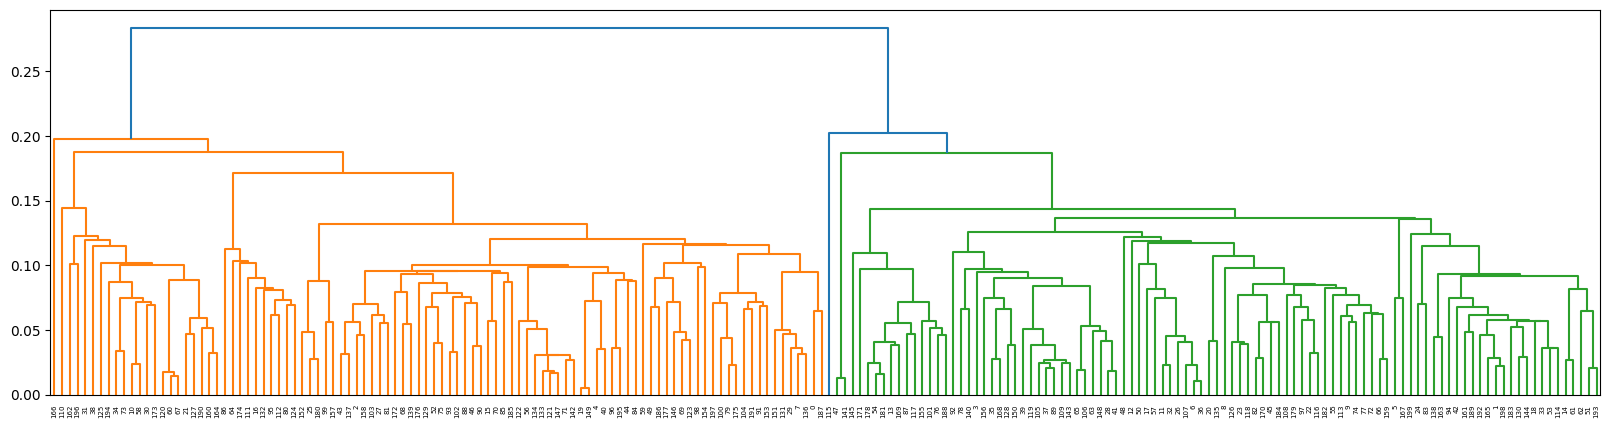

In [10]:
# Dataset #2 and show dendrogram.
myLinkage = linkage(X2, method='single')       # Cluster hierarchically using single linkage.
plt.figure(figsize=(20, 5))
dendrogram(myLinkage)
plt.show()

In [11]:
# Dataset #2 and clusters by cutting the dendrogram.
labels = fcluster(myLinkage, 0.23, criterion='distance')                      #  Cut at the height (distance) = 0.23 <= change this value at will.
pd.Series(labels).value_counts()

,count
1,100
2,100


Resultado: Éxito total.   

Comportamiento: Divide los datos exactamente en dos grupos iguales (100 y 100).   

Causa: Como la distancia de corte (0.23) es menor al espacio vacío que separa ambas medialunas, el árbol se divide limpiamente en dos ramas principales.

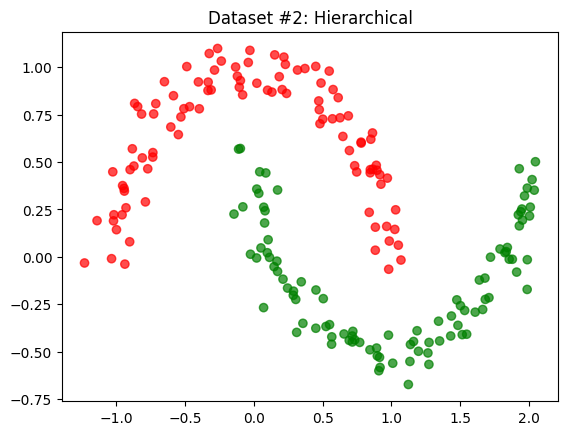

In [12]:
myColors = {1: 'red', 2: 'green'}                                                # Define a color palette: 1~2.
plt.scatter(X2[:, 0], X2[:, 1], c=pd.Series(labels).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #2: Hierarchical')
plt.show()

Resultado: Separación perfecta de la geometría.   

Comportamiento: Cada medialuna queda pintada de un color distinto siguiendo toda la curva.   

Conclusión: Aquí el "efecto cadena" fue una ventaja: fue saltando de vecino en vecino a lo largo de cada curva sin cruzarse a la otra, logrando lo que K-Means no pudo.

#### 1.5. Apply DBSCAN and visualize:

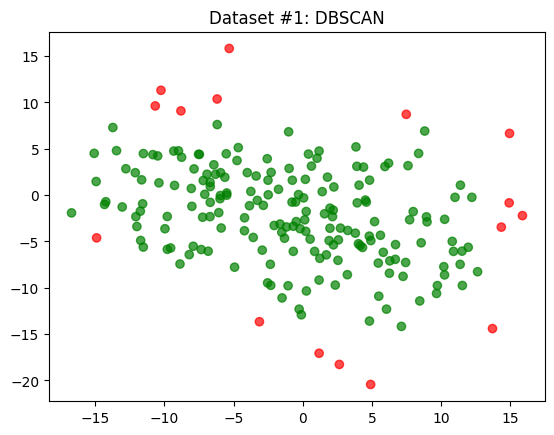

In [13]:
# Dataset #1.
dbscan = DBSCAN(eps=3, min_samples=5)
dbscan.fit(X1)
myColors = {-1: 'red', 0: 'green', 1: 'blue'}                                 # Define a color palette: -1~1.  Red = -1 = outlier.
plt.scatter(X1[:, 0], X1[:, 1], c=pd.Series(dbscan.labels_).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #1: DBSCAN')
plt.show()

Resultado: Falla al separar los dos grupos originales.   

Comportamiento: Une casi todos los datos en un solo grupo verde y marca los puntos de los extremos como ruido (rojos).   

Causa: DBSCAN busca vacíos de densidad. Como ambos grupos se mezclan en el centro, el algoritmo ve un camino continuo y los junta en uno solo.

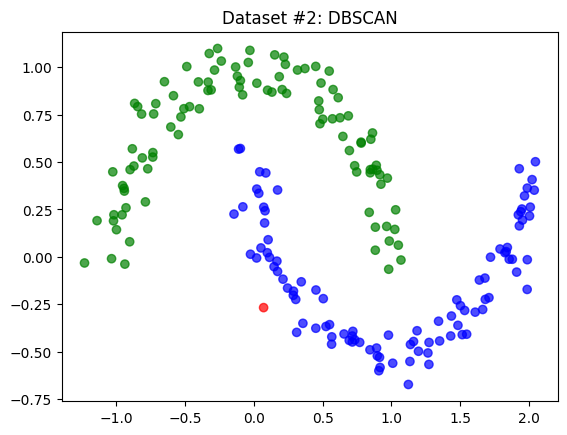

In [14]:
# Dataset #2.
dbscan = DBSCAN(eps=0.2, min_samples=5)
dbscan.fit(X2)
myColors = {-1: 'red', 0: 'green', 1: 'blue'}                                 # Define a color palette: -1~1. Red = -1 = outlier.
plt.scatter(X2[:, 0], X2[:, 1], c=pd.Series(dbscan.labels_).apply(lambda x: myColors[x]), alpha=0.7 )
plt.title('Dataset #2: DBSCAN')
plt.show()

Resultado: Éxito total.   

Comportamiento: Separa perfectamente las dos curvas (verde y azul) sin cortar ninguna.   

Ventajas: No asume formas circulares, no necesita que le digamos cuántos grupos buscar ($k$) y aísla los puntos raros como ruido (el punto rojo).

### Comparación de Algoritmos de Clustering

| Algoritmo | Dataset #1: Blobs dispersos | Dataset #2: Medialunas (No lineal) | Causa técnica principal |
| :--- | :--- | :--- | :--- |
| **K-Means** | Funciona bien | Falla (parte las curvas por la mitad) | Asume clusters convexos/esféricos y fronteras de decisión lineales basadas en centroides. |
| **Aglomerativo (Ward)** | Funciona bien | Falla (corta las trayectorias curvas) | Minimiza la varianza cuadrática intra-cluster, tendiendo por defecto a formar grupos compactos y redondeados. |
| **Jerárquico (Single Linkage)** | Falla (1 cluster gigante + outliers) | **Éxito total** (100% y 100%) | El criterio de distancia mínima genera encadenamiento (*chaining effect*), conectando puntos continuos a lo largo de formas arbitrarias. |
| **DBSCAN** | Falla (fusiona en un único cluster grande) | **Éxito total** (+ detección de ruido) | Agrupa por densidad conectada sin asumir geometrías predefinidas; no requiere fijar el número $k$ de antemano. |   